In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")



In [83]:
import os
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ealaxi/paysim1")

df=pd.read_csv(os.path.join(path,"PS_20174392719_1491204439457_log.csv"))


Using Colab cache for faster access to the 'paysim1' dataset.


In [84]:
df.shape

(6362620, 11)

In [85]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [87]:
df.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [88]:
df.sample(5)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
440022,18,CASH_OUT,70180.14,C557587812,55463.93,0.00,C344642426,0.00,70180.14,0,0
2801807,225,CASH_OUT,78156.98,C2147145756,6072.00,0.00,C1960981750,583201.48,661358.46,0,0
4745948,333,CASH_OUT,30995.08,C1262459682,533326.00,502330.92,C256555803,0.00,30995.08,0,0
5141944,356,PAYMENT,33161.97,C2020204427,88412.69,55250.72,M1033621151,0.00,0.00,0,0
3374227,254,PAYMENT,18928.06,C913671221,0.00,0.00,M203583498,0.00,0.00,0,0


In [89]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
step,6362620.0,2.433972e+02,1.423320e+02,1.0,156.00,239.000,3.350000e+02,7.430000e+02
amount,6362620.0,1.798619e+05,6.038582e+05,0.0,13389.57,74871.940,2.087215e+05,9.244552e+07
oldbalanceOrg,6362620.0,8.338831e+05,2.888243e+06,0.0,0.00,14208.000,1.073152e+05,5.958504e+07
newbalanceOrig,6362620.0,8.551137e+05,2.924049e+06,0.0,0.00,0.000,1.442584e+05,4.958504e+07
oldbalanceDest,6362620.0,1.100702e+06,3.399180e+06,0.0,0.00,132705.665,9.430367e+05,3.560159e+08
newbalanceDest,6362620.0,1.224996e+06,3.674129e+06,0.0,0.00,214661.440,1.111909e+06,3.561793e+08
isFraud,6362620.0,1.290820e-03,3.590480e-02,0.0,0.00,0.000,0.000000e+00,1.000000e+00
isFlaggedFraud,6362620.0,2.514687e-06,1.585775e-03,0.0,0.00,0.000,0.000000e+00,1.000000e+00


In [90]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [91]:
df['isFraud'].value_counts()

,count
isFraud,
0,6354407
1,8213


In [92]:
df.dtypes

,0
step,int64
type,object
amount,float64
nameOrig,object
oldbalanceOrg,float64
newbalanceOrig,float64
nameDest,object
oldbalanceDest,float64
newbalanceDest,float64
isFraud,int64


In [93]:
df.duplicated().sum()

np.int64(0)

In [94]:
print("Fraud Distribution:")
print(df["isFraud"].value_counts())

print("\nFraud Percentage:")
print(df["isFraud"].value_counts(normalize=True) * 100)

Fraud Distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud Percentage:
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


In [95]:
df['type'].value_counts(normalize=True) * 100


,proportion
type,
CASH_OUT,35.166331
PAYMENT,33.814608
CASH_IN,21.992261
TRANSFER,8.375622
DEBIT,0.651178


In [96]:
df['type'].value_counts()


,count
type,
CASH_OUT,2237500
PAYMENT,2151495
CASH_IN,1399284
TRANSFER,532909
DEBIT,41432


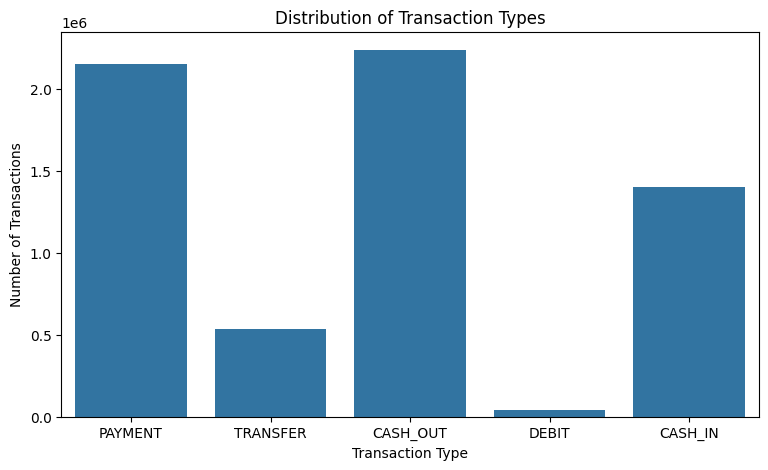

In [97]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="type")

plt.title("Distribution of Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.show()


In [98]:
fraud_by_type = df[df["isFraud"] == 1]["type"].value_counts()
print(fraud_by_type)

type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64


In [99]:
# Calculate fraud rate for each transaction type

fraud_rate = df.groupby("type")["isFraud"].mean() * 100

print(fraud_rate.sort_values(ascending=False))

type
TRANSFER    0.768799
CASH_OUT    0.183955
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64


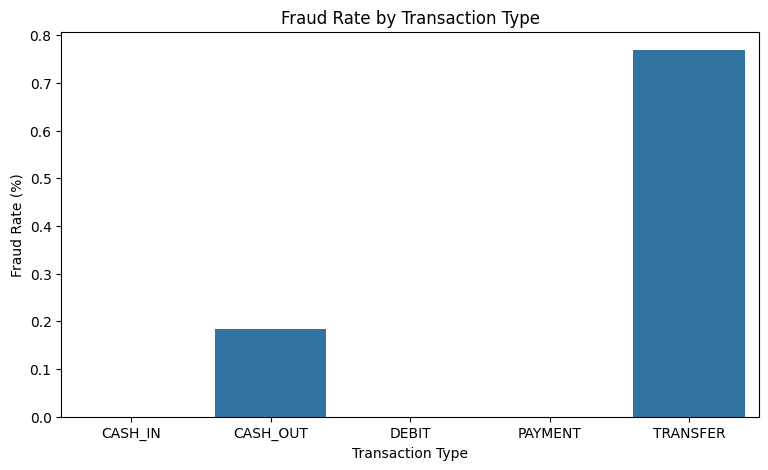

In [100]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=fraud_rate.index,
    y=fraud_rate.values
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")

plt.show()

In [101]:
amount_analysis=df.groupby('isFraud')['amount'].describe()
print(amount_analysis)

             count          mean           std   min         25%        50%  \
isFraud                                                                       
0        6354407.0  1.781970e+05  5.962370e+05  0.01   13368.395   74684.72   
1           8213.0  1.467967e+06  2.404253e+06  0.00  127091.330  441423.44   

                75%          max  
isFraud                           
0         208364.76  92445516.64  
1        1517771.48  10000000.00  


In [102]:
print("Average Legitimate Transaction:",
      df[df["isFraud"] == 0]["amount"].mean())

print("Average Fraudulent Transaction:",
      df[df["isFraud"] == 1]["amount"].mean())

Average Legitimate Transaction: 178197.0417274075
Average Fraudulent Transaction: 1467967.2991403872


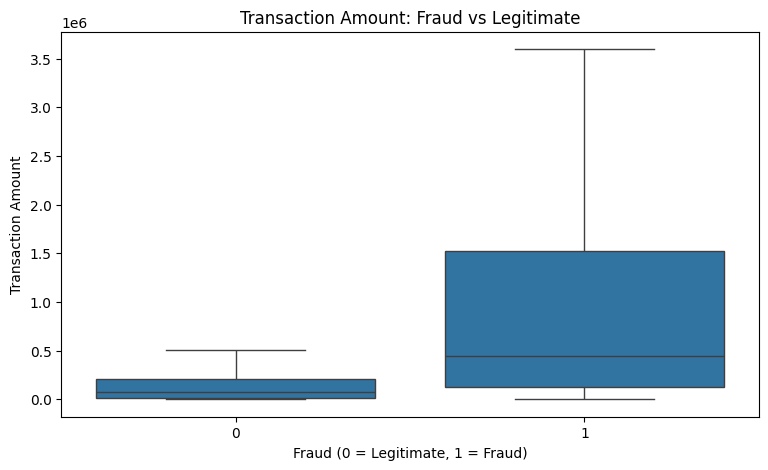

In [103]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="isFraud",
    y="amount",
    showfliers=False
)

plt.title("Transaction Amount: Fraud vs Legitimate")
plt.xlabel("Fraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.show()

In [104]:
fraud_by_time = (
    df[df["isFraud"] == 1]
    .groupby("step")
    .size()
)

print(fraud_by_time.head(10))

step
1     16
2      8
3      4
4     10
5      6
6     22
7     12
8     12
9     19
10    11
dtype: int64


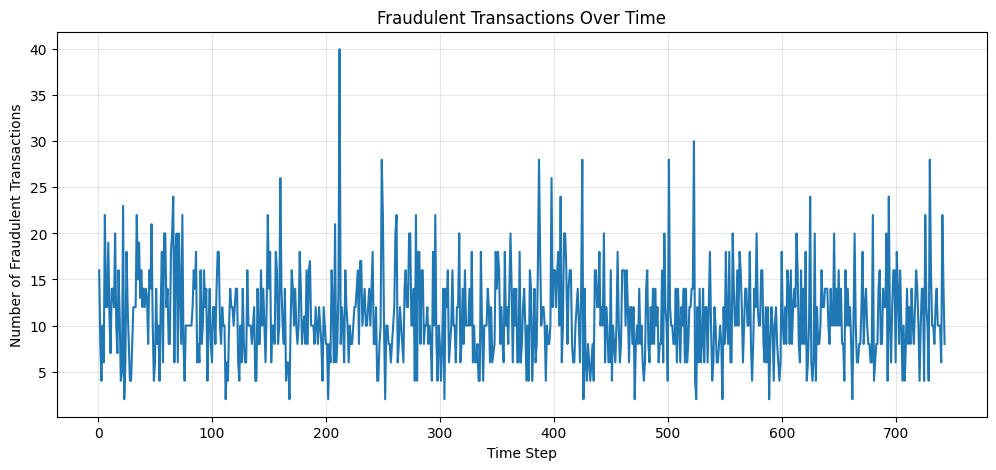

In [105]:
plt.figure(figsize=(12, 5))

plt.plot(fraud_by_time.index, fraud_by_time.values)

plt.title("Fraudulent Transactions Over Time")
plt.xlabel("Time Step")
plt.ylabel("Number of Fraudulent Transactions")

plt.grid(alpha=0.3)
plt.show()

In [106]:
balance_analysis = df.groupby("isFraud")[
    ["oldbalanceOrg", "newbalanceOrig"]
].mean()

print(balance_analysis)

         oldbalanceOrg  newbalanceOrig
isFraud                               
0         8.328287e+05   855970.228109
1         1.649668e+06   192392.631836


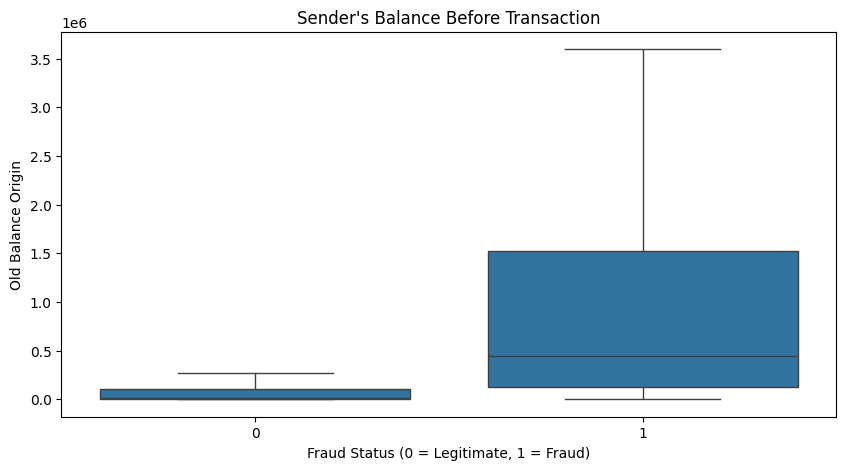

In [107]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="isFraud",
    y="oldbalanceOrg",
    showfliers=False
)

plt.title("Sender's Balance Before Transaction")
plt.xlabel("Fraud Status (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Old Balance Origin")

plt.show()

In [108]:
df.groupby(["isFraud", "type"])[
    ["oldbalanceOrg", "newbalanceOrig"]
].mean()

oldbalanceOrg  newbalanceOrig
isFraud type                                   
0       CASH_IN    3.590464e+06    3.759379e+06
        CASH_OUT   4.342923e+04    1.750626e+04
        DEBIT      6.864734e+04    6.516165e+04
        PAYMENT    6.821683e+04    6.183789e+04
        TRANSFER   4.055876e+04    7.380372e+03
1       CASH_OUT   1.453869e+06    7.258688e+01
        TRANSFER   1.846374e+06    3.856046e+05

In [109]:

dest_type_analysis = df.groupby(
    ["isFraud", "type"]
)[["oldbalanceDest", "newbalanceDest"]].mean()

print(dest_type_analysis)

                  oldbalanceDest  newbalanceDest
isFraud type                                    
0       CASH_IN     1.587919e+06    1.467105e+06
        CASH_OUT    1.498519e+06    1.689744e+06
        DEBIT       1.493136e+06    1.513003e+06
        PAYMENT     0.000000e+00    0.000000e+00
        TRANSFER    2.587490e+06    3.582075e+06
1       CASH_OUT    1.084918e+06    2.549545e+06
        TRANSFER    1.073383e+03    3.981411e+03


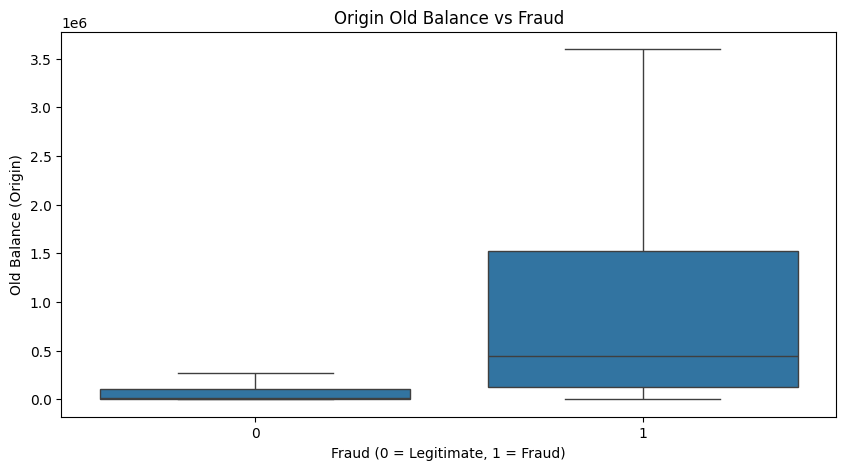

In [110]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="isFraud",
    y="oldbalanceOrg",
    showfliers=False
)

plt.title("Origin Old Balance vs Fraud")
plt.xlabel("Fraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Old Balance (Origin)")
plt.show()

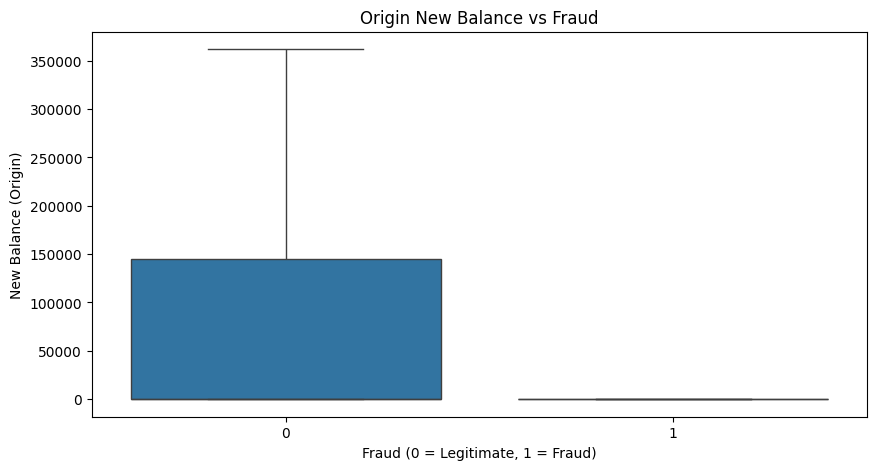

In [111]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="isFraud",
    y="newbalanceOrig",
    showfliers=False
)

plt.title("Origin New Balance vs Fraud")
plt.xlabel("Fraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("New Balance (Origin)")
plt.show()

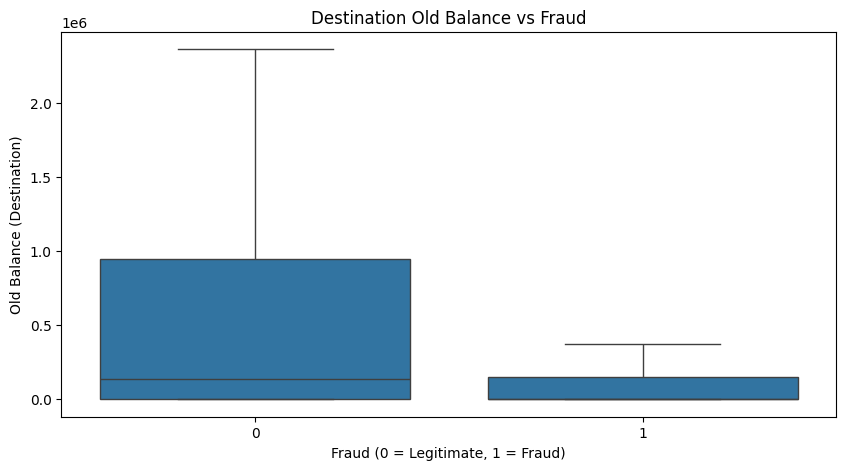

In [112]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="isFraud",
    y="oldbalanceDest",
    showfliers=False
)

plt.title("Destination Old Balance vs Fraud")
plt.xlabel("Fraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Old Balance (Destination)")
plt.show()

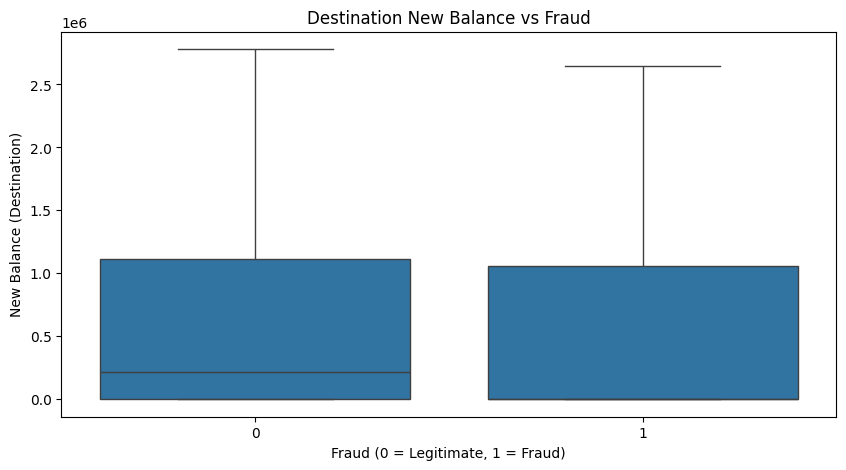

In [113]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="isFraud",
    y="newbalanceDest",
    showfliers=False
)

plt.title("Destination New Balance vs Fraud")
plt.xlabel("Fraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("New Balance (Destination)")
plt.show()

In [114]:
orig_error = (
    df["oldbalanceOrg"] - df["newbalanceOrig"] - df["amount"]
)

print("Origin Balance Error:")
print(df.groupby("isFraud").apply(
    lambda x: orig_error.loc[x.index].describe()
))

Origin Balance Error:
             count           mean            std          min        25%  \
isFraud                                                                    
0        6354407.0 -201338.558109  606928.890826 -92445516.64 -249953.43   
1           8213.0  -10692.325265  265146.131130 -10000000.00       0.00   

              50%       75%           max  
isFraud                                    
0       -69049.31 -3034.305  1.000000e-02  
1            0.00     0.000  3.725290e-09  


In [115]:
dest_error = (
    df["newbalanceDest"] - df["oldbalanceDest"] - df["amount"]
)

print("Destination Balance Error:")
print(df.groupby("isFraud").apply(
    lambda x: dest_error.loc[x.index].describe()
))

Destination Balance Error:
             count           mean           std          min         25%  \
isFraud                                                                    
0        6354407.0  -54692.231734  4.360026e+05 -13191233.98  -29259.805   
1           8213.0 -732509.301069  1.867748e+06 -10000000.00 -442722.010   

             50%  75%          max  
isFraud                             
0       -3500.68  0.0  75885725.63  
1       -2231.46  0.0   8875516.29  


In [116]:
numerical_df=df.select_dtypes(exclude=object)
numerical_df=numerical_df.drop(columns=['isFlaggedFraud'])
numerical_df.columns

Index(['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest', 'isFraud'],
      dtype='object')

In [117]:
correlation=numerical_df.corr()
print(correlation['isFraud'])

step              0.031578
amount            0.076688
oldbalanceOrg     0.010154
newbalanceOrig   -0.008148
oldbalanceDest   -0.005885
newbalanceDest    0.000535
isFraud           1.000000
Name: isFraud, dtype: float64


<Axes: >

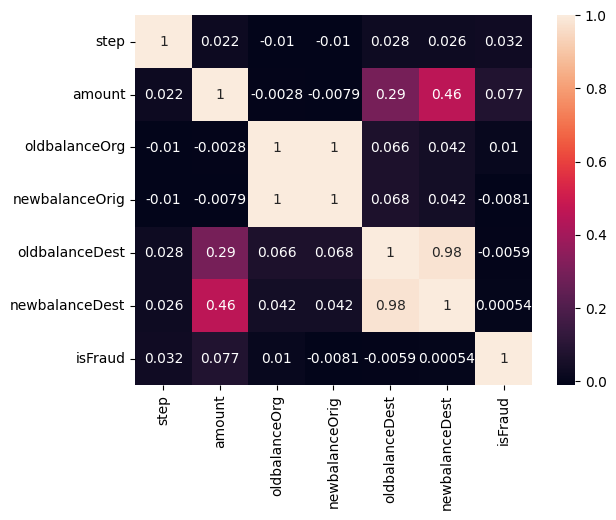

In [118]:
sns.heatmap(numerical_df.corr(),annot=True)

In [119]:
fraud_rate = df.groupby("type")["isFraud"].mean() * 100

print(fraud_rate.sort_values(ascending=False))

type
TRANSFER    0.768799
CASH_OUT    0.183955
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64


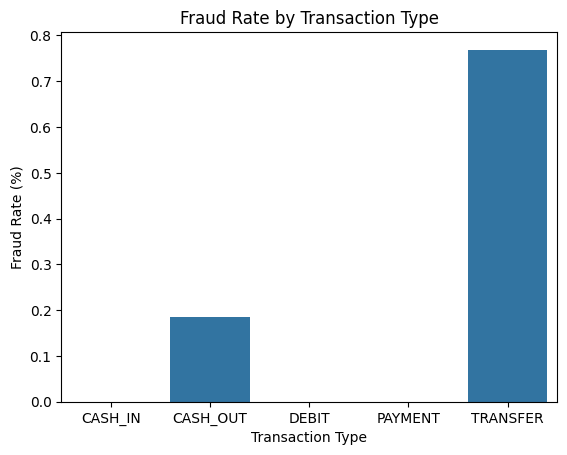

In [120]:
sns.barplot(x=fraud_rate.index,y=fraud_rate.values)
plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.show()

In [121]:
print("Unique Origin Accounts:", df["nameOrig"].nunique())
print("Unique Destination Accounts:", df["nameDest"].nunique())

Unique Origin Accounts: 6353307
Unique Destination Accounts: 2722362


In [122]:
print(df["nameOrig"].value_counts().head(10))


nameOrig
C1530544995    3
C545315117     3
C724452879     3
C1784010646    3
C1677795071    3
C1462946854    3
C1065307291    3
C1999539787    3
C2098525306    3
C400299098     3
Name: count, dtype: int64


In [123]:
print(df["nameDest"].value_counts().head(10))

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C1789550256     99
C451111351      99
C1360767589     98
C1023714065     97
Name: count, dtype: int64


In [124]:
dest_fraud = df.groupby("nameDest").agg(
    total_transactions=("isFraud", "count"),
    fraud_transactions=("isFraud", "sum")
)

dest_fraud = dest_fraud.sort_values(
    by="fraud_transactions",
    ascending=False
)

print(dest_fraud.head(10))

             total_transactions  fraud_transactions
nameDest                                           
C1827219533                  24                   2
C1780714769                   6                   2
C1366192319                  12                   2
C1148781766                   2                   2
C1325541393                  32                   2
C1399829166                  25                   2
C686334805                    2                   2
C644163395                   26                   2
C904300960                   32                   2
C1193568854                  37                   2


In [125]:
account_fraud = df.groupby(
    ["nameOrig"]
).agg(
    total_transactions=("isFraud", "count"),
    fraud_transactions=("isFraud", "sum")
)

print("Top Origin Accounts by Fraud:")
print(account_fraud.sort_values(
    "fraud_transactions", ascending=False
).head(10))

Top Origin Accounts by Fraud:
             total_transactions  fraud_transactions
nameOrig                                           
C1652159172                   1                   1
C349513899                    1                   1
C498550702                    1                   1
C1184786020                   1                   1
C1964503568                   1                   1
C1827869035                   1                   1
C46599562                     1                   1
C764461588                    1                   1
C1558861751                   1                   1
C1615152184                   1                   1


In [126]:
dest_fraud_filtered = dest_fraud[
    dest_fraud["total_transactions"] >= 10
].copy()

dest_fraud_filtered["fraud_rate"] = (
    dest_fraud_filtered["fraud_transactions"]
    / dest_fraud_filtered["total_transactions"]
) * 100

print(
    dest_fraud_filtered.sort_values(
        "fraud_rate", ascending=False
    ).head(10)
)

             total_transactions  fraud_transactions  fraud_rate
nameDest                                                       
C2129197098                  10                   2   20.000000
C1460854172                  12                   2   16.666667
C1366192319                  12                   2   16.666667
C1497532505                  12                   2   16.666667
C1656842502                  12                   2   16.666667
C935310781                   14                   2   14.285714
C967226405                   14                   2   14.285714
C105660024                   15                   2   13.333333
C1601170327                  16                   2   12.500000
C643624257                   17                   2   11.764706


In [127]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(df["type"], df["isFraud"])

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square Statistic:", chi2)
print("P-value:", p_value)


Chi-square Statistic: 22082.53571319108
P-value: 0.0


In [128]:


df_sorted=df.sort_values(by='step')
unique_steps=df_sorted['step'].unique()
split_index=int(len(unique_steps)* 0.8 )
cutoff_step=unique_steps[split_index]


df_train=df_sorted[df_sorted['step']<cutoff_step]
df_test=df_sorted[df_sorted['step']>=cutoff_step]

In [129]:
X_train=df_train.drop(columns=["isFraud", "isFlaggedFraud", "nameOrig", "nameDest"])

y_train=df_train["isFraud"]

X_test = df_test.drop(
    columns=["isFraud", "isFlaggedFraud", "nameOrig", "nameDest"]
)
y_test = df_test["isFraud"]

In [130]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((6239040, 7), (6239040,), (123580, 7), (123580,))

In [131]:
print("training target distribution")
print(y_train.value_counts())

print("\ntesting target distribution")
print(y_test.value_counts())


print("\nTraining fraud percentage:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting fraud percentage:")
print(y_test.value_counts(normalize=True) * 100)



training target distribution
isFraud
0    6232481
1       6559
Name: count, dtype: int64

testing target distribution
isFraud
0    121926
1      1654
Name: count, dtype: int64

Training fraud percentage:
isFraud
0    99.894872
1     0.105128
Name: proportion, dtype: float64

Testing fraud percentage:
isFraud
0    98.661596
1     1.338404
Name: proportion, dtype: float64


In [132]:
print("Training fraud cases:", y_train.sum())
print("Testing fraud cases:", y_test.sum())

Training fraud cases: 6559
Testing fraud cases: 1654


In [133]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler



categorical_col=['type']
numerical_col=['step','amount','oldbalanceOrg','newbalanceOrig','oldbalanceDest','newbalanceDest']


preprocessor=ColumnTransformer(
    transformers=[
       ( "cat",OneHotEncoder(handle_unknown="ignore"),categorical_col),
        ("num",StandardScaler(),numerical_col)
    ]
)


pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]
)


In [134]:
pipeline.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type']),
                                                 ('num', StandardScaler(),
                                                  ['step', 'amount',
                                                   'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [135]:
y_pred=pipeline.predict(X_test)

In [136]:
print(f"predictions : {y_pred.shape}")
print("\nPrediction distribution:")
print(pd.Series(y_pred).value_counts())

predictions : (123580,)

Prediction distribution:
0    109701
1     13879
Name: count, dtype: int64


In [137]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.90      0.95    121926
           1       0.12      0.99      0.21      1654

    accuracy                           0.90    123580
   macro avg       0.56      0.95      0.58    123580
weighted avg       0.99      0.90      0.94    123580



In [138]:
 from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[109692  12234]
 [     9   1645]]


In [139]:
X_sample = X_train.sample(
    n=500_000,
    random_state=42
)

y_sample = y_train.loc[X_sample.index]

print("Sample distribution:")
print(y_sample.value_counts())

print("\nSample fraud percentage:")
print(y_sample.value_counts(normalize=True) * 100)

print("Original training fraud rate:")
print(y_train.mean() * 100)

print("\nSample fraud rate:")
print(y_sample.mean() * 100)

Sample distribution:
isFraud
0    499479
1       521
Name: count, dtype: int64

Sample fraud percentage:
isFraud
0    99.8958
1     0.1042
Name: proportion, dtype: float64
Original training fraud rate:
0.10512835307996103

Sample fraud rate:
0.1042


In [140]:
from sklearn.ensemble import RandomForestClassifier


rf_preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_col),
        ("num", "passthrough", numerical_col)
    ]
)

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [141]:
import time

start_time = time.time()

rf_pipeline.fit(X_sample, y_sample)

end_time = time.time()

print("Training time:", round(end_time - start_time, 2), "seconds")

Training time: 68.23 seconds


In [142]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_rf=rf_pipeline.predict(X_test)

print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    121926
           1       1.00      0.69      0.81      1654

    accuracy                           1.00    123580
   macro avg       1.00      0.84      0.91    123580
weighted avg       1.00      1.00      1.00    123580



In [143]:
print(classification_report(y_test, y_pred_rf, digits=4))

cm_rf = confusion_matrix(y_test, y_pred_rf)
print("Confusion Matrix:")
print(cm_rf)

              precision    recall  f1-score   support

           0     0.9958    1.0000    0.9979    121926
           1     1.0000    0.6862    0.8139      1654

    accuracy                         0.9958    123580
   macro avg     0.9979    0.8431    0.9059    123580
weighted avg     0.9958    0.9958    0.9954    123580

Confusion Matrix:
[[121926      0]
 [   519   1135]]


In [144]:
import joblib
joblib.dump(
    rf_pipeline,
    "fraud_detection_model.pkl"
)

['fraud_detection_model.pkl']